# 02 – Baseline forecast and fixed timetable

**Purpose:** set up the two reference solutions every later model must beat (report Section 4, *Alternative solutions*), and the shared scoring used for validation (Section 5).

1. **Fixed timetable** – HVAC on 7 am–7 pm, Mon–Fri. No forecast at all; represents typical building practice (an *assumed* schedule – the real Monash schedule was not supplied).
2. **Profile baseline** – forecast = historical average headcount for that space, weekday and hour.

Both are scored on the **2025 validation period**, which neither has seen. The 2026 test period is kept aside for the final comparison.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from occupancy import clean, evaluate, plots
from occupancy.models import ProfileBaseline, FixedTimetable
from occupancy.config import PROCESSED_DIR, FIGURES_DIR, REPO_ROOT

hourly = clean.load_hourly(PROCESSED_DIR / "occupancy_hourly.csv")
split = evaluate.chronological_split(hourly)
pd.DataFrame({k: {"hours": len(v), "from": v["date"].min(), "to": v["date"].max(),
                  "spaces": ", ".join(sorted(v["space"].unique()))} for k, v in split.items()}).T

,hours,from,to,spaces
train,29069,2023-11-24,2024-12-31,"G.20 Breakout, G.25 MSM Lab, Space A, Space B,..."
validation,24759,2025-01-01,2025-12-31,"G.20 Breakout, G.25 MSM Lab, Space A, Space B"
test,7160,2026-01-01,2026-04-22,"G.20 Breakout, G.25 MSM Lab, Space A, Space B"


## 1. Definition of "occupied"
An hour counts as **occupied when its mean headcount is at least 1 person**. A lower threshold (0.5) would label about a quarter of 2–4 am hours as occupied, which reflects night-time sensor background (~0.5 people) rather than real use.

In [2]:
h = hourly
night, afternoon = h["hour_of_day"].between(2, 4), h["hour_of_day"].between(13, 15) & (h["day_type"] == "Weekday")
pd.DataFrame({thr: {"2–4 am counted occupied": (h.loc[night, "mean_headcount"] >= thr).mean(),
                    "weekday 1–3 pm counted occupied": (h.loc[afternoon, "mean_headcount"] >= thr).mean()}
              for thr in [0.5, 1.0, 1.5]}).style.format("{:.0%}")

,0.500000,1.000000,1.500000
2–4 am counted occupied,26%,11%,4%
weekday 1–3 pm counted occupied,95%,87%,73%


## 2. Fit and score on the 2025 validation period

In [3]:
train, val = split["train"], split["validation"]
baseline = ProfileBaseline().fit(train)
timetable = FixedTimetable(start_hour=7, end_hour=19, weekdays_only=True)

results = pd.DataFrame([
    evaluate.score_schedule(val, timetable.schedule(val), "Fixed timetable (7am–7pm weekdays)"),
    evaluate.score_forecast(val, baseline.predict(val), "Profile baseline"),
]).set_index("approach")
cols = ["hours", "mae", "rmse", "correct_on", "wasted", "discomfort", "correct_off", "wasted_rate", "discomfort_rate", "accuracy"]
results_dir = REPO_ROOT / "reports" / "results"; results_dir.mkdir(exist_ok=True)
results[cols].to_csv(results_dir / "stage2_validation.csv")
results[cols].round(3)

,hours,mae,rmse,correct_on,wasted,discomfort,correct_off,wasted_rate,discomfort_rate,accuracy
approach,,,,,,,,,,
Fixed timetable (7am–7pm weekdays),24759,NaN,NaN,8087,3504,3239,9929,0.261,0.286,0.728
Profile baseline,24759,0.753,1.368,9505,4927,1821,8506,0.367,0.161,0.727


**Reading the table:** `wasted` = hours conditioned while empty; `discomfort` = occupied hours left unconditioned. `mae` is the average forecast miss in people (not applicable to the timetable, which makes no forecast).

## 3. Results by space

In [4]:
rows = []
for space, d in val.groupby("space"):
    rows.append({"space": space, **evaluate.score_schedule(d, timetable.schedule(d), "Timetable")})
    rows.append({"space": space, **evaluate.score_forecast(d, baseline.predict(d), "Baseline")})
pd.DataFrame(rows).pivot(index="space", columns="approach", values=["mae", "wasted_rate", "discomfort_rate"]).round(3)

mae           wasted_rate           discomfort_rate  \
approach      Baseline Timetable    Baseline Timetable        Baseline   
space                                                                    
G.20 Breakout    1.346       NaN       0.699     0.375           0.062   
G.25 MSM Lab     0.789       NaN       0.343     0.262           0.198   
Space A          0.554       NaN       0.457     0.290           0.141   
Space B          0.466       NaN       0.138     0.172           0.241   

                         
approach      Timetable  
space                    
G.20 Breakout     0.296  
G.25 MSM Lab      0.345  
Space A           0.275  
Space B           0.235

## 4. Example week (Figure 4)

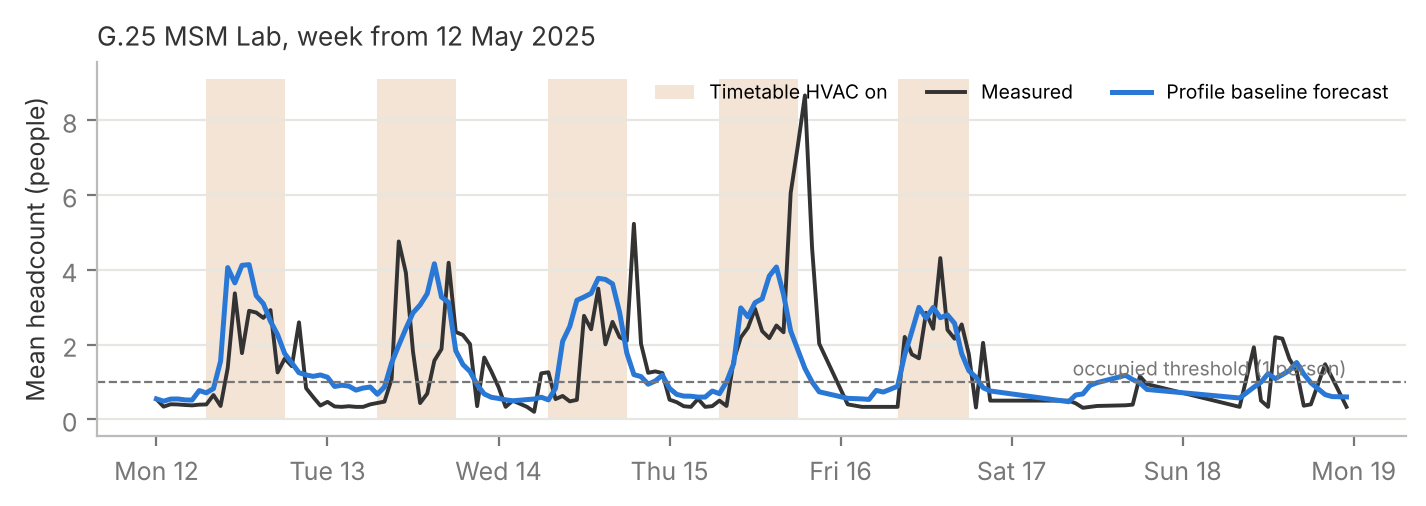

In [5]:
fig = plots.example_week(val.assign(baseline=baseline.predict(val), timetable=timetable.schedule(val)),
                         space="G.25 MSM Lab", start="2025-05-12")
fig.savefig(FIGURES_DIR / "fig4_example_week.png", facecolor="white")

## 5. Observations
* Neither reference dominates: the **timetable** wastes fewer hours but leaves many occupied hours (evenings, weekends) unconditioned; the **profile baseline** cuts discomfort roughly in half but conditions more empty hours, because an *average* of ≥1 person does not mean every such hour is occupied.
* Both make the same decision for every Tuesday 2 pm regardless of what is actually happening this week – this is the gap the machine-learning model (Stage 3) is meant to close, by also using recent occupancy.
* The threshold choice (1 person) shifts the balance between wasted and discomfort hours; its sensitivity is analysed in Stage 4.